In [14]:
from sklearn.datasets import load_iris
import numpy as np
import pandas as pd

iris = load_iris()

In [2]:
import pandas as pd

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
df.rename(
    columns={
        'target': 'Species',
        'sepal length (cm)': 'SepalLengthCm',
        'sepal width (cm)': 'SepalWidthCm',
        'petal length (cm)': 'PetalLengthCm',
        'petal width (cm)': 'PetalWidthCm'
    },
    inplace=True
)


In [4]:
df.sample(10)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
117,7.7,3.8,6.7,2.2,2
127,6.1,3.0,4.9,1.8,2
75,6.6,3.0,4.4,1.4,1
67,5.8,2.7,4.1,1.0,1
123,6.3,2.7,4.9,1.8,2
92,5.8,2.6,4.0,1.2,1
82,5.8,2.7,3.9,1.2,1
65,6.7,3.1,4.4,1.4,1
93,5.0,2.3,3.3,1.0,1
73,6.1,2.8,4.7,1.2,1


In [5]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


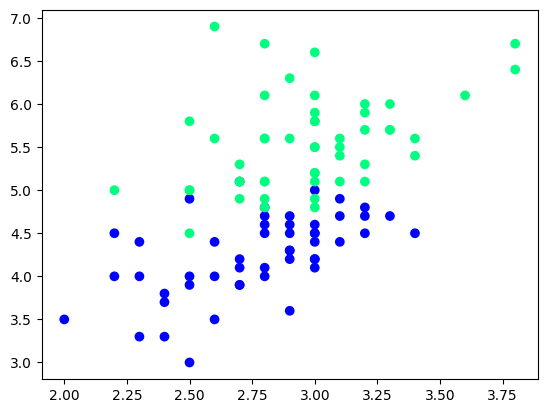

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')



In [7]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
60,2.0,3.5,1
103,2.9,5.6,2
80,2.4,3.8,1
100,3.3,6.0,2
102,3.0,5.9,2
79,2.6,3.5,1
66,3.0,4.5,1
58,2.9,4.6,1
71,2.8,4.0,1
67,2.7,4.1,1


In [8]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

df_train

,SepalWidthCm,PetalLengthCm,Species
58,2.9,4.6,1
53,2.3,4.0,1
69,2.5,3.9,1
99,2.8,4.1,1
70,3.2,4.8,1
133,2.8,5.1,2
131,3.8,6.4,2
127,3.0,4.9,2
141,3.1,5.1,2
137,3.1,5.5,2


In [9]:
df_val

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
130,2.8,6.1,2
117,3.8,6.7,2
118,2.6,6.9,2
139,3.1,5.4,2


In [10]:
df_test

,SepalWidthCm,PetalLengthCm,Species
77,3.0,5.0,1
112,3.0,5.5,2
148,3.4,5.4,2
88,3.0,4.1,1
93,2.3,3.3,1


In [11]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values
y_test

array([2, 2, 2, 2, 2])

# Case 1 - Bagging

In [12]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
53,2.3,4.0,1
141,3.1,5.1,2
69,2.5,3.9,1
53,2.3,4.0,1
70,3.2,4.8,1
70,3.2,4.8,1
127,3.0,4.9,2
141,3.1,5.1,2


In [16]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

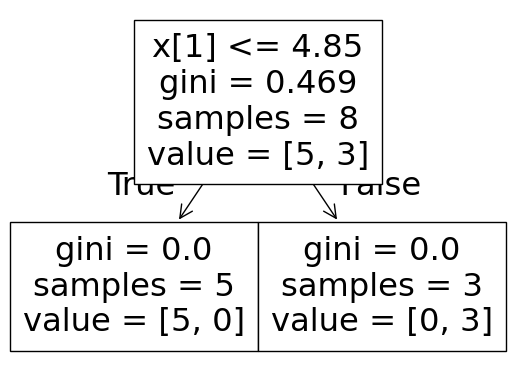

1.0


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


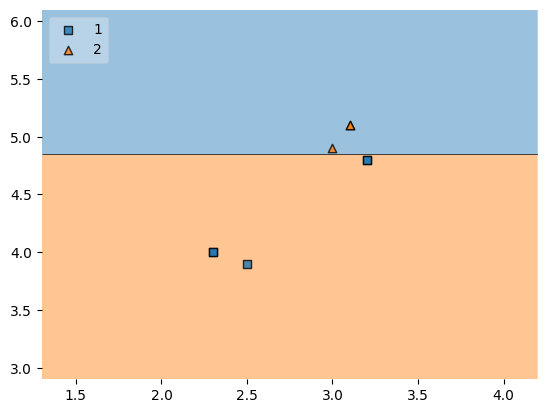

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

dt_bag1 = DecisionTreeClassifier()

evaluate(dt_bag1,X,y)

In [18]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
99,2.8,4.1,1
133,2.8,5.1,2
137,3.1,5.5,2
137,3.1,5.5,2
133,2.8,5.1,2
58,2.9,4.6,1
131,3.8,6.4,2
141,3.1,5.1,2


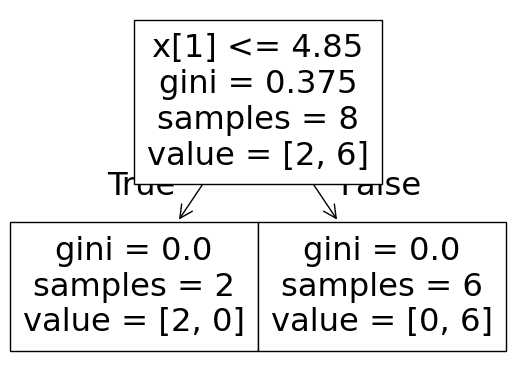

1.0


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


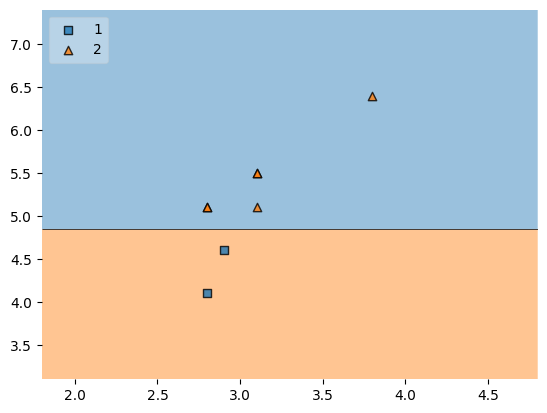

In [19]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [20]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
127,3.0,4.9,2
131,3.8,6.4,2
58,2.9,4.6,1
99,2.8,4.1,1
99,2.8,4.1,1
141,3.1,5.1,2
58,2.9,4.6,1
127,3.0,4.9,2


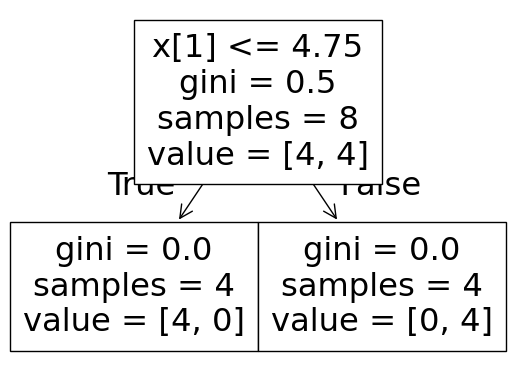

1.0


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


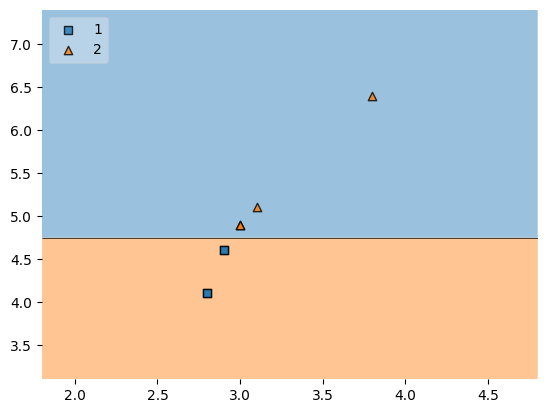

In [21]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

# Predict

In [22]:
df_test


,SepalWidthCm,PetalLengthCm,Species
77,3.0,5.0,1
112,3.0,5.5,2
148,3.4,5.4,2
88,3.0,4.1,1
93,2.3,3.3,1


In [23]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [24]:
df_train

,SepalWidthCm,PetalLengthCm,Species
58,2.9,4.6,1
53,2.3,4.0,1
69,2.5,3.9,1
99,2.8,4.1,1
70,3.2,4.8,1
133,2.8,5.1,2
131,3.8,6.4,2
127,3.0,4.9,2
141,3.1,5.1,2
137,3.1,5.5,2


In [25]:
df_train.sample(8)


,SepalWidthCm,PetalLengthCm,Species
131,3.8,6.4,2
70,3.2,4.8,1
137,3.1,5.5,2
99,2.8,4.1,1
127,3.0,4.9,2
53,2.3,4.0,1
141,3.1,5.1,2
69,2.5,3.9,1


# Random Subspaces

In [26]:
df.sample(2,replace=True,axis=1)


,Species,PetalLengthCm
141,2,5.1
74,1,4.3
102,2,5.9
128,2,5.6
69,1,3.9
...,...,...
93,1,3.3
88,1,4.1
77,1,5.0
148,2,5.4


# Random Patches


In [27]:
df.sample(8,replace=True).sample(2,replace=True,axis=1)


,Species,SepalWidthCm
94,1,2.7
56,1,3.3
125,2,3.2
103,2,2.9
50,1,3.2
128,2,2.8
56,1,3.3
60,1,2.0
